In [1]:
import os, time, json, random, warnings
import numpy as np, torch
import deepchem as dc
from sklearn.metrics import roc_auc_score
from openpom.feat.graph_featurizer import GraphConvConstants
from openpom.utils.data_utils import get_class_imbalance_ratio
from openpom.models.mpnn_pom import MPNNPOMModel
warnings.filterwarnings("ignore", category=FutureWarning)

DATA = os.path.expanduser("~/ai-nose/data")
ENS  = os.path.expanduser("~/ai-nose/models/ensemble")
train = dc.data.DiskDataset(f"{DATA}/train")
valid = dc.data.DiskDataset(f"{DATA}/valid")
test  = dc.data.DiskDataset(f"{DATA}/test")
train_ratios = get_class_imbalance_ratio(train)
metric = dc.metrics.Metric(dc.metrics.roc_auc_score)

def make_model(model_dir):
    lr = dc.models.optimizers.ExponentialDecay(
        initial_rate=0.001, decay_rate=0.5, decay_steps=32*20, staircase=True)
    return MPNNPOMModel(
        n_tasks=len(train.tasks), batch_size=128, learning_rate=lr,
        class_imbalance_ratio=train_ratios, loss_aggr_type="sum",
        node_out_feats=100, edge_hidden_feats=75, edge_out_feats=100,
        num_step_message_passing=5, mpnn_residual=True, message_aggregator_type="sum",
        mode="classification", number_atom_features=GraphConvConstants.ATOM_FDIM,
        number_bond_features=GraphConvConstants.BOND_FDIM, n_classes=1,
        readout_type="set2set", num_step_set2set=3, num_layer_set2set=2,
        ffn_hidden_list=[392, 392], ffn_embeddings=256, ffn_activation="relu",
        ffn_dropout_p=0.12, ffn_dropout_at_input_no_act=False, weight_decay=1e-5,
        self_loop=False, optimizer_name="adam", log_frequency=32,
        model_dir=model_dir, device_name="cuda")

def mean_auroc(y_true, y_prob):
    # AUROC for each of the 138 smell words, then the average
    return float(np.mean([roc_auc_score(y_true[:, j], y_prob[:, j]) for j in range(y_true.shape[1])]))

N_MODELS, MAX_EPOCHS, PATIENCE, CHECK_EVERY = 10, 100, 30, 5

# 1. Train 10 models, each from a different random starting point
for i in range(N_MODELS):
    out = f"{ENS}/model_{i}"
    if os.path.exists(f"{out}/done.json"):
        print(f"model {i}: already trained, skipping")
        continue
    print(f"model {i}: training...", flush=True)
    seed = 1000 + i
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    os.makedirs(f"{out}/best", exist_ok=True)
    model = make_model(out)
    best_valid, best_epoch, start = 0.0, 0, time.time()
    for epoch in range(1, MAX_EPOCHS + 1):
        model.fit(train, nb_epoch=1, max_checkpoints_to_keep=1,
                  deterministic=False, restore=epoch > 1)
        if epoch % CHECK_EVERY == 0:
            va = model.evaluate(valid, [metric])["roc_auc_score"]
            if va > best_valid:
                best_valid, best_epoch = va, epoch
                model.save_checkpoint(max_checkpoints_to_keep=1, model_dir=f"{out}/best")
            if epoch - best_epoch >= PATIENCE:
                break   # early stopping: no improvement for 30 epochs
    model.restore(model_dir=f"{out}/best")
    test_auroc = model.evaluate(test, [metric])["roc_auc_score"]
    mins = (time.time() - start) / 60
    json.dump({"seed": seed, "best_epoch": best_epoch, "valid_auroc": best_valid,
               "test_auroc": test_auroc, "minutes": mins}, open(f"{out}/done.json", "w"))
    print(f"model {i}: best epoch {best_epoch} | valid {best_valid:.3f} | test {test_auroc:.3f} | {mins:.1f} min")
    del model; torch.cuda.empty_cache()

# 2. Ensemble: average the 10 models' predicted probabilities on the test set
probs = []
for i in range(N_MODELS):
    m = make_model(f"{ENS}/model_{i}")
    m.restore(model_dir=f"{ENS}/model_{i}/best")
    probs.append(np.asarray(m.predict(test)).reshape(len(test), -1))
    del m; torch.cuda.empty_cache()
ens = np.mean(probs, axis=0)
np.save(f"{ENS}/test_ensemble_probs.npy", ens)   # saved for later analysis

singles = [mean_auroc(test.y, p) for p in probs]
print(f"\nSingle models: average test AUROC {np.mean(singles):.3f} (range {min(singles):.3f} to {max(singles):.3f})")
print(f"ENSEMBLE of {N_MODELS}: test AUROC {mean_auroc(test.y, ens):.3f}")

No normalization for SPS. Feature removed!
No normalization for AvgIpc. Feature removed!
No normalization for NumAmideBonds. Feature removed!
No normalization for NumAtomStereoCenters. Feature removed!
No normalization for NumBridgeheadAtoms. Feature removed!
No normalization for NumHeterocycles. Feature removed!
No normalization for NumSpiroAtoms. Feature removed!
No normalization for NumUnspecifiedAtomStereoCenters. Feature removed!
No normalization for Phi. Feature removed!
Skipped loading material featurizer, missing a dependency. No module named 'ase'
/home/sachinkukkar/miniforge3/envs/open_pom/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Skipped loading some Tensorflow models, missing a dependency. No module named 'tensorflow'
Skipped loading some PyTorch models, missing a dependency. No module

model 0: training...
model 0: best epoch 65 | valid 0.878 | test 0.872 | 11.6 min
model 1: training...
model 1: best epoch 45 | valid 0.882 | test 0.876 | 7.7 min
model 2: training...
model 2: best epoch 65 | valid 0.881 | test 0.878 | 10.4 min
model 3: training...
model 3: best epoch 45 | valid 0.881 | test 0.878 | 10.6 min
model 4: training...
model 4: best epoch 45 | valid 0.883 | test 0.879 | 8.7 min
model 5: training...
model 5: best epoch 50 | valid 0.881 | test 0.877 | 9.0 min
model 6: training...
model 6: best epoch 55 | valid 0.885 | test 0.877 | 23.2 min
model 7: training...
model 7: best epoch 90 | valid 0.880 | test 0.877 | 16.0 min
model 8: training...
model 8: best epoch 30 | valid 0.879 | test 0.874 | 5.4 min
model 9: training...
model 9: best epoch 45 | valid 0.882 | test 0.873 | 20.4 min

Single models: average test AUROC 0.876 (range 0.872 to 0.879)
ENSEMBLE of 10: test AUROC 0.891


In [2]:
import glob
import pandas as pd
import matplotlib.pyplot as plt
from rdkit import Chem
from rdkit.Chem import Draw
from IPython.display import display
from openpom.feat.graph_featurizer import GraphFeaturizer

TASKS = list(train.tasks)
featurizer = GraphFeaturizer()

# Load the 10 trained models once
models = []
for i in range(N_MODELS):
    m = make_model(f"{ENS}/model_{i}")
    m.restore(model_dir=f"{ENS}/model_{i}/best")
    models.append(m)

def canon(s):
    mol = Chem.MolFromSmiles(s)
    return Chem.MolToSmiles(mol) if mol else None

# Which split each molecule is in, plus its catalogue smell words
split_of = {canon(s): name for name, ds in [("train", train), ("valid", valid), ("test", test)] for s in ds.ids}
path = glob.glob(os.path.expanduser("~/openpom/**/*4983*.csv"), recursive=True)[0]
df_all = pd.read_csv(path)
true_desc = {canon(s): d for s, d in zip(df_all["nonStereoSMILES"], df_all["descriptors"])}

def predict_smells(smiles, top=10):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        print("Couldn't read that SMILES. Check it and try again.")
        return
    X = dc.data.NumpyDataset(featurizer.featurize([smiles]))
    p = np.mean([np.asarray(m.predict(X)).reshape(-1) for m in models], axis=0)

    key = canon(smiles)
    where = split_of.get(key)
    if where is None:
        print("NEW molecule: the model has never seen it.")
    elif where == "test":
        print("TEST-set molecule: never used in training, so this is a fair test.")
    elif where == "valid":
        print("VALIDATION-set molecule: not trained on, but used to pick the best epoch.")
    else:
        print("TRAINING-set molecule: the model has seen it, so this is NOT a fair test.")
    if key in true_desc:
        print("Catalogue smell words:", true_desc[key].replace(";", ", "))

    display(Draw.MolToImage(mol, size=(250, 250)))
    idx = np.argsort(p)[::-1][:top]
    plt.figure(figsize=(6, 4))
    plt.barh([TASKS[j] for j in idx][::-1], p[idx][::-1])
    plt.xlabel("predicted probability")
    plt.title(f"Top {top} predicted smells")
    plt.tight_layout()
    plt.show()

print("Ready: 10 models loaded")

Ready: 10 models loaded


TEST-set molecule: never used in training, so this is a fair test.
Catalogue smell words: fruity, chocolate, pungent, cocoa, malty, green, musty


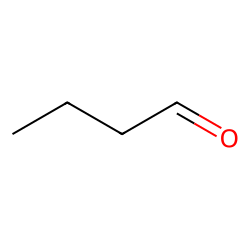

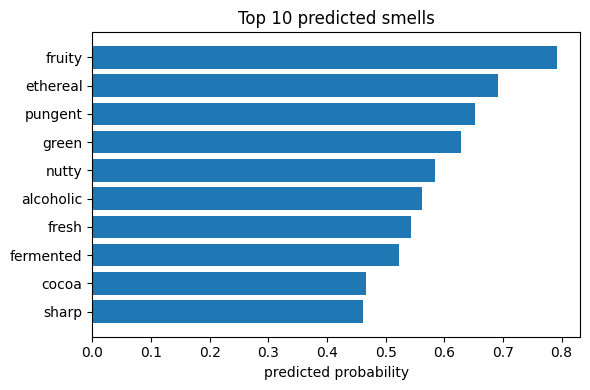

In [3]:
predict_smells(test.ids[0])

TRAINING-set molecule: the model has seen it, so this is NOT a fair test.
Catalogue smell words: chocolate, vanilla, creamy, sweet


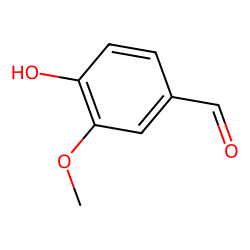

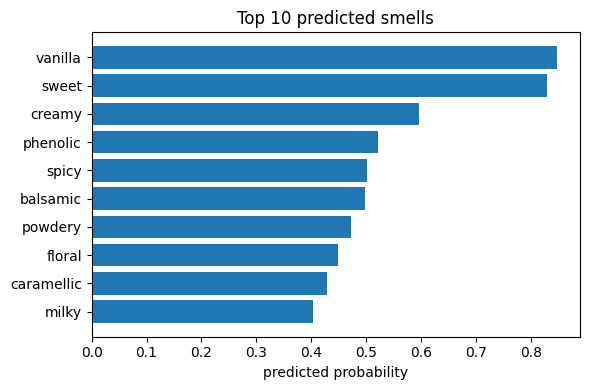

In [4]:
predict_smells("COc1cc(C=O)ccc1O")